# Building a Strategic Portfolio



In [1]:
%pip install yfinance


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from scipy.optimize import minimize
from scipy.stats import skew, kurtosis, chi2

In [ ]:
# ── Data acquisition ──────────────────────────────────────────
tickers        = sorted(["SPY", "GLD", "VNQ", "TLT", "QQQ", "^GDAXI"])
start_date     = "2010-01-01"
end_date       = "2024-12-31"
risk_free_rate = 0.02

def fetch_asset_data(tickers, start_date, end_date):
    data = yf.download(tickers, start=start_date, end=end_date, progress=False)
    if "Adj Close" in [c[0] for c in data.columns]:
        prices = data["Adj Close"]
    else:
        prices = data["Close"]
    prices.columns = [c.replace(".", "_") for c in prices.columns]
    return prices.dropna()

asset_prices   = fetch_asset_data(tickers, start_date, end_date)
market_prices  = fetch_asset_data(["SPY"], start_date, end_date)
returns        = asset_prices.pct_change().dropna()
returns_market = market_prices.pct_change().dropna()

print("Asset prices loaded:", asset_prices.shape)
asset_prices.head()

Asset prices loaded: (3708, 6)


,GLD,QQQ,SPY,TLT,VNQ,^GDAXI
Date,,,,,,
2010-01-04,109.800003,40.290783,84.796364,55.928661,23.552092,6048.299805
2010-01-05,109.699997,40.290783,85.020844,56.289837,23.525661,6031.859863
2010-01-06,111.510002,40.047756,85.080765,55.536327,23.483370,6034.330078
2010-01-07,110.820000,40.073803,85.439857,55.629749,23.737135,6019.359863
2010-01-08,111.370003,40.403625,85.724182,55.604828,23.562672,6037.609863


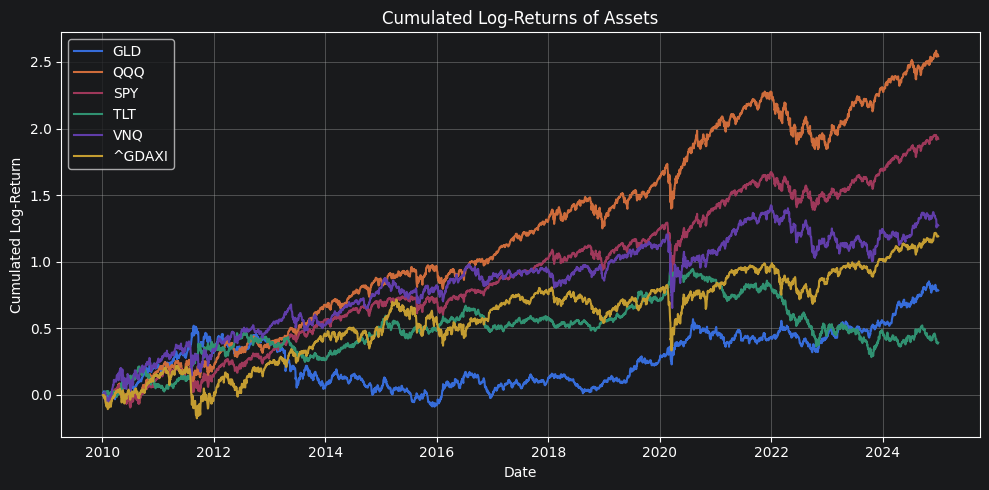

In [ ]:
# ── Cumulative log-returns ────────────────────────────────────
log_returns          = np.log(asset_prices / asset_prices.shift(1)).dropna()
cumulative_log_returns = log_returns.cumsum()

plt.figure(figsize=(10, 5))
for ticker in cumulative_log_returns.columns:
    plt.plot(cumulative_log_returns.index, cumulative_log_returns[ticker], label=ticker)
plt.title("Cumulated Log-Returns of Assets")
plt.xlabel("Date")
plt.ylabel("Cumulated Log-Return")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

---
## Jarque-Bera Normality Test

The **Jarque-Bera (JB) test** checks whether returns are normally distributed using skewness $S$ and (Pearson) kurtosis $K$:

$$JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right)$$

Under the null hypothesis of normality, $JB \sim \chi^2(2)$, so the p-value is $1 - F_{\chi^2(2)}(JB)$.


In [ ]:
def test_normality(returns):
    """
    Jarque-Bera normality test for each asset.

    """
    results = {}
    for asset in returns.columns:
        data = returns[asset].dropna()
        n    = len(data)

        skew_val = stats.skew(data)   # skewness
        kurt_val = stats.kurtosis(data, fisher=False)   # Pearson kurtosis (fisher=False)
        jb_stat  = n/6*(skew_val**2+((kurt_val-3)**2/4))   # JB formula
        p_value  = 1 - chi2.cdf(jb_stat, df=2)   # p-value from chi2(df=2)
        # ────────────────────────────────────────────────────────────────────

        results[asset] = {
            "JB Statistic": jb_stat,
            "p-value":      p_value,
            "Skewness":     skew_val,
            "Kurtosis":     kurt_val,
        }
    return pd.DataFrame(results).T


normality_results = test_normality(returns)
normality_results

,JB Statistic,p-value,Skewness,Kurtosis
GLD,3033.908050,0.0,-0.399641,7.359288
QQQ,5582.361944,0.0,-0.356785,8.969284
SPY,17837.124051,0.0,-0.524934,13.694838
TLT,1840.561130,0.0,0.057182,6.450094
VNQ,38779.793539,0.0,-0.754637,18.773132
^GDAXI,7903.236202,0.0,-0.311418,10.125974


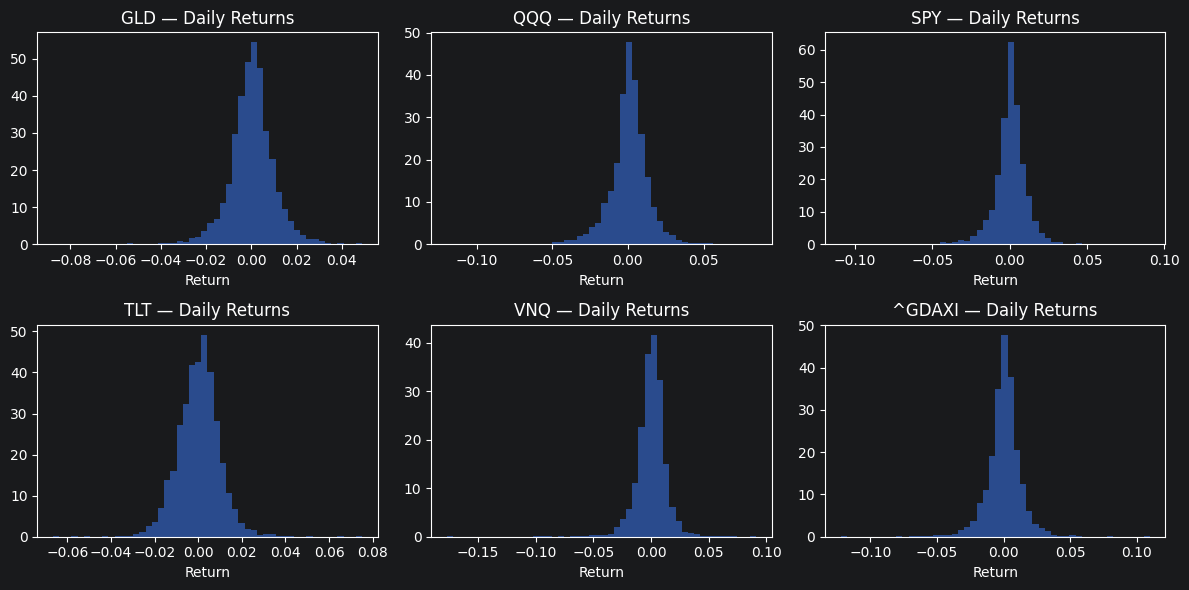

In [ ]:
# Return distribution histograms  
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()
for i, asset in enumerate(returns.columns):
    axes[i].hist(returns[asset], bins=50, density=True, alpha=0.6)
    axes[i].set_title(f"{asset} — Daily Returns")
    axes[i].set_xlabel("Return")
plt.tight_layout()
plt.show()

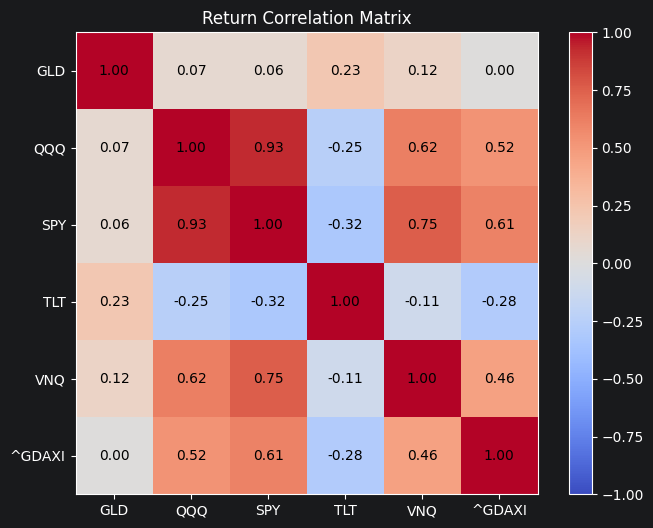

In [ ]:
# Correlation matrix
correlation_matrix = returns.corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax)
for i in range(len(correlation_matrix)):
    for j in range(len(correlation_matrix)):
        ax.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}",
                ha="center", va="center", color="black")
ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))
ax.set_xticklabels(correlation_matrix.columns)
ax.set_yticklabels(correlation_matrix.columns)
plt.title("Return Correlation Matrix")
plt.show()

---
## Investment Opportunity Set & Efficient Frontier 

**Mean-Variance framework:**
$$\mu_p = \mathbf{w}^\top \boldsymbol{\mu}, \quad \sigma_p = \sqrt{\mathbf{w}^\top \Sigma \mathbf{w}}$$

The **Efficient Frontier** is the set of portfolios that minimise $\sigma_p$ for each target $\mu_p$.


In [ ]:

mu = returns.mean() * 252

Sigma = returns.cov() * 252

def portfolio_return(weights):

    return weights @ mu

def portfolio_volatility(weights):

    return np.sqrt(weights @ Sigma @ weights)

def portfolio_sharpe(weights):

    return portfolio_return(weights) - risk_free_rate / portfolio_volatility(weights)

def calculate_efficient_frontier(mu, Sigma):
    # Step 1: flatten mu to 1D array so shapes don't cause issues
    mu_arr = np.array(mu).ravel()

    # Step 2: convert Sigma to a plain NumPy matrix
    sig_arr = np.array(Sigma)

    # Step 3: number of assets
    n = mu_arr.size

    # Step 4: each weight between 0% and 40%
    bounds = [(0, 0.4)] * n

    # Step 5: weights must sum to 1
    eq_sum = {"type": "eq", "fun": lambda w: np.sum(w) - 1}

    # Step 6: find the minimum-variance portfolio
    mv_res = minimize(
        lambda w: np.sqrt(w @ sig_arr @ w),
        np.ones(n) / n,
        method="SLSQP",
        bounds=bounds,
        constraints=[eq_sum]
    )

    # Step 7: use the min-variance return as the lower bound for target returns
    mv_ret = mv_res.x @ mu_arr if mv_res.success else mu_arr.min()

    # Step 8: warm-start subsequent optimizations from the min-variance weights
    x0 = mv_res.x if mv_res.success else np.ones(n) / n

    # Step 9: 50 evenly-spaced target returns from min-variance up to max possible
    targets = np.linspace(mv_ret, mu_arr.max(), 50)

    # Step 10: list to collect one weight vector per frontier point
    weights_list = []

    # Step 11: for each target return, find the portfolio with minimum volatility
    for target in targets:
        res = minimize(
            lambda w: np.sqrt(w @ sig_arr @ w),
            x0,
            method="SLSQP",
            bounds=bounds,
            constraints=[
                eq_sum,
                {"type": "eq", "fun": lambda w: w @ mu_arr - target}
            ]
        )
        if res.success:
            weights_list.append(res.x)
            x0 = res.x

    # Step 12: return all frontier portfolios
    return weights_list

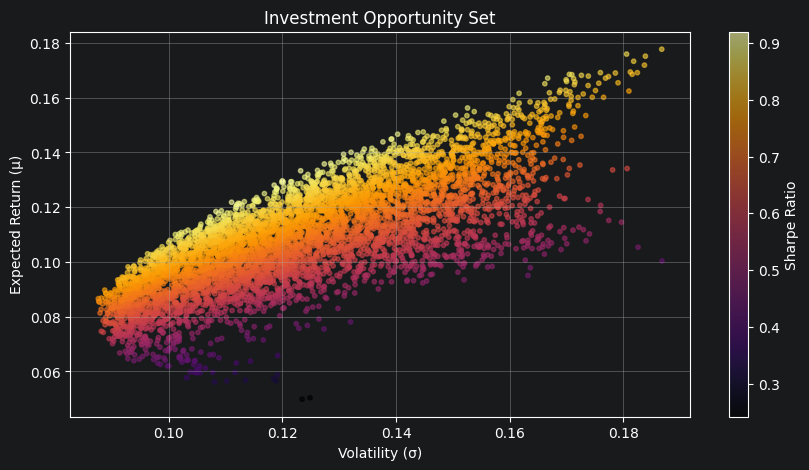

In [ ]:
# Investment Opportunity Set scatter 
np.random.seed(42)
n_portfolios = 5000
all_weights  = np.random.dirichlet(np.ones(len(mu)), size=n_portfolios)
ret_list     = [portfolio_return(w)    for w in all_weights]
vol_list     = [portfolio_volatility(w) for w in all_weights]
sr_list      = [(r - risk_free_rate) / v for r, v in zip(ret_list, vol_list)]

plt.figure(figsize=(10, 5))
plt.scatter(vol_list, ret_list, c=sr_list, cmap="inferno", s=10, alpha=0.6)
plt.colorbar(label="Sharpe Ratio")
plt.title("Investment Opportunity Set")
plt.xlabel("Volatility (σ)")
plt.ylabel("Expected Return (μ)")
plt.grid(True)
plt.show()

---
## Tangency Portfolio & Optimal Complete Portfolio  

The **Tangency Portfolio** maximises the Sharpe Ratio:
$$\text{Sharpe} = \frac{\mu_p - R_f}{\sigma_p}$$

The **Optimal Complete Portfolio** mixes the tangency portfolio with the risk-free asset based on risk aversion $A$:
$$y^* = \min\!\left(\frac{\mu_p - R_f}{A \cdot \sigma_p^2},\; 1\right)$$

In [ ]:
# ── Tangency Portfolio & Optimal Complete Portfolio ───────────────
def find_tangency_portfolio(mu, Sigma, risk_free_rate):


    # Step 1:
    # Convert mu into a one-dimensional NumPy array.
    # This avoids shape problems such as (n, 1) instead of (n,).
    mu_arr = np.array(mu)

    # Step 2:
    # Convert Sigma into a NumPy array.
    sig_arr = np.matrix(Sigma)

    # Step 3:
    # Get the number of assets.
    n = mu_arr.size

    # Step 4:
    # Define the objective function.
    def neg_sharpe(w):
        ret = w @ mu_arr

        vol = np.sqrt(w @ sig_arr @ w)

        return - (ret - risk_free_rate) / vol

    # Step 5:
    # Define the initial guess.
    # A common starting point is an equally weighted portfolio.
    x0 = np.ones(n) / n

    # Step 6:
    # Define the bounds.
    # In this assignment, each asset weight should be between 0% and 40%.
    bounds = [(0, 0.4)] * n

    # Step 7:
    # Define the full-investment constraint.
    constraint = {"type": "eq", "fun": lambda w: np.sum(w) - 1}


    # Step 8:
    # Use scipy.optimize.minimize() to find the portfolio weights
    # that minimize the negative Sharpe ratio.
    res = minimize(neg_sharpe, x0, method="SLSQP", bounds=bounds, constraints=constraint)

    # Step 9:
    if res.success:
        return res.x
    else:
        return x0

def optimal_complete_portfolio(tangency_weights, mu, Sigma, rf=0.02, A=9):
    """
    Calculate the optimal allocation to the risky tangency portfolio.

    Parameters
    ----------
    tangency_weights : array-like
        Weights of the tangency portfolio.

    mu : array-like
        Expected returns of the assets.

    Sigma : array-like
        Covariance matrix of asset returns.

    rf : float, optional
        Risk-free rate. Default is 0.02.

    A : float, optional
        Risk-aversion parameter. Default is 9.

    Returns
    -------
    y_star : float
        Fraction of total wealth invested in the risky tangency portfolio.

    Notes
    -----
    The optimal risky allocation is:

        y* = (E[R_p] - r_f) / (A * sigma_p^2)

    where:

        E[R_p]     = expected return of the tangency portfolio
        r_f        = risk-free rate
        A          = risk-aversion parameter
        sigma_p^2  = variance of the tangency portfolio

    If y* = 1, the investor puts 100% in the risky tangency portfolio.
    If y* = 0.5, the investor puts 50% in the risky tangency portfolio
    and 50% in the risk-free asset.
    """

    # Step 1:
    # Convert inputs into NumPy arrays.
    weights = np.asarray(tangency_weights)
    mu_arr = np.asarray(mu)
    sig_arr = np.asarray(Sigma)

    # Step 2:
    # Calculate the expected return of the tangency portfolio.
    rp = weights @ mu_arr

    # Step 3:
    # Calculate the variance of the tangency portfolio.
    variance_p = weights @ sig_arr @ weights

    # Step 4:
    # Calculate y_star.
    y_star = (rp - rf) / (A * variance_p)

    # Step 5:
    # Optional: restrict y_star to a maximum of 1.0
    y_star = min(y_star, 1.0)

    # Step 6:
    # Return the optimal risky allocation.
    return y_star



# Store at module level
tangency_weights = find_tangency_portfolio(mu, Sigma, risk_free_rate)
y_star           = optimal_complete_portfolio(tangency_weights, mu, Sigma)

print("Tangency weights:")
for t, w in zip(tickers, tangency_weights):
    print(f"  {t:8s}: {w*100:.2f}%")
print(f"\ny* (allocation to tangency portfolio): {y_star*100:.2f}%")

Tangency weights:
  GLD     : 14.31%
  QQQ     : 40.00%
  SPY     : 14.47%
  TLT     : 27.98%
  VNQ     : 0.00%
  ^GDAXI  : 3.23%

y* (allocation to tangency portfolio): 90.95%


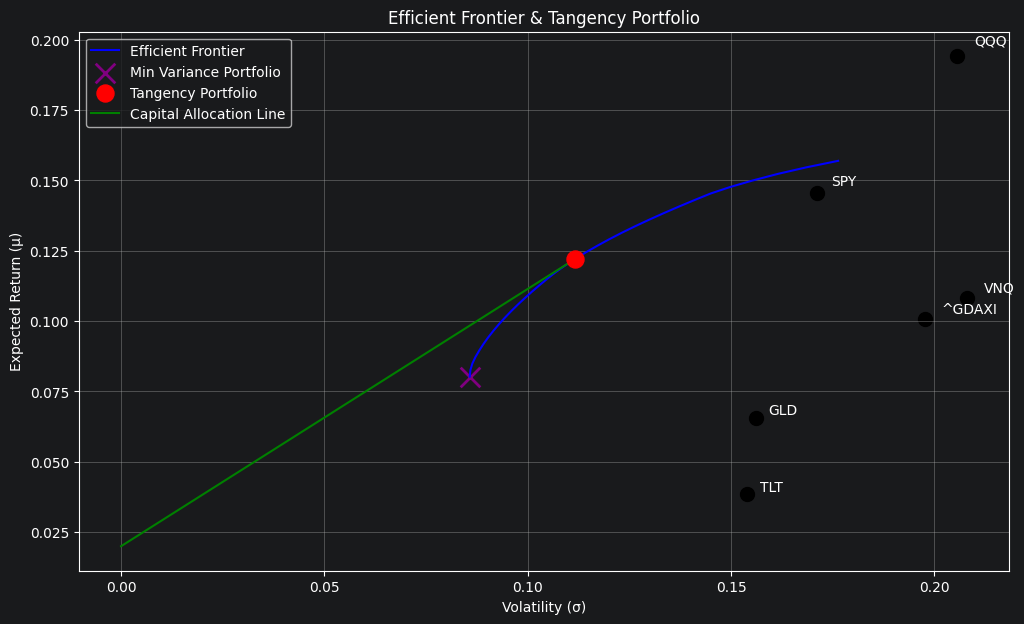

Tangency: E[R]=12.21%  σ=11.17%  Sharpe=0.914


In [ ]:
# Efficient Frontier + Tangency Portfolio plot
efficient_weights      = calculate_efficient_frontier(mu, Sigma)
efficient_returns      = [portfolio_return(w)    for w in efficient_weights]
efficient_volatilities = [portfolio_volatility(w) for w in efficient_weights]

tangency_return     = portfolio_return(tangency_weights)
tangency_volatility = portfolio_volatility(tangency_weights)

plt.figure(figsize=(12, 7))
plt.plot(efficient_volatilities, efficient_returns, "b-", label="Efficient Frontier")

min_vol_idx = np.argmin(efficient_volatilities)
plt.scatter(efficient_volatilities[min_vol_idx], efficient_returns[min_vol_idx],
            marker="x", s=200, c="purple", linewidths=2, label="Min Variance Portfolio")

asset_vols = np.sqrt(np.diag(np.asarray(Sigma)))
for i, ticker in enumerate(tickers):
    plt.scatter(asset_vols[i], float(np.asarray(mu).ravel()[i]), c="k", s=100)
    plt.text(asset_vols[i]*1.02, float(np.asarray(mu).ravel()[i])*1.02, ticker, fontsize=10)

plt.scatter(tangency_volatility, tangency_return, c="r", s=150, zorder=5, label="Tangency Portfolio")

x_cal = np.linspace(0, max(efficient_volatilities)*1.1, 100)
y_cal = risk_free_rate + (tangency_return - risk_free_rate) / tangency_volatility * x_cal
plt.plot(x_cal[x_cal <= tangency_volatility], y_cal[x_cal <= tangency_volatility],
         "g-", label="Capital Allocation Line")

plt.xlabel("Volatility (σ)")
plt.ylabel("Expected Return (μ)")
plt.title("Efficient Frontier & Tangency Portfolio")
plt.legend()
plt.grid(True)
plt.show()

print(f"Tangency: E[R]={tangency_return*100:.2f}%  σ={tangency_volatility*100:.2f}%  "
      f"Sharpe={(tangency_return-risk_free_rate)/tangency_volatility:.3f}")

---
## Risk Decomposition via OLS Regression  

Decompose portfolio returns into systematic (market) and idiosyncratic components:
$$R_p - R_f = \alpha + \beta(R_m - R_f) + \varepsilon$$

Risk decomposition:
$$\sigma_p^2 = (\beta \cdot \sigma_m)^2 + \sigma_\varepsilon^2$$

Return decomposition (annualised):
$$\text{Total Return} = \underbrace{\beta \cdot E[R_m - R_f] \cdot 252 + R_f}_{\text{Systematic}} + \underbrace{\alpha \cdot 252}_{\text{Idiosyncratic}}$$

In [ ]:
# ── Task 4: OLS Risk Decomposition ───────────────────────────────────────
def perform_risk_analysis(portfolio_weights, returns):

    # Step 1:
    # Convert portfolio weights into a NumPy array.
    weights = np.asarray(portfolio_weights)

    # Step 2:
    # Calculate daily portfolio returns.
    portfolio_returns = returns @ weights

    # Step 3:
    # Define the market return.
    market_returns = returns["SPY"]

    # Step 4:
    # Convert the annual risk-free rate into a daily risk-free rate.
    daily_rf = risk_free_rate / 252

    # Step 5:
    # Calculate excess returns.
    portfolio_excess = portfolio_returns - daily_rf
    market_excess = market_returns - daily_rf

    # Step 6:
    # Align the portfolio and market excess return series.
    idx = portfolio_excess.index.intersection(market_excess.index)

    portfolio_excess = portfolio_excess.loc[idx]
    market_excess = market_excess.loc[idx]

    # Step 7:
    # Prepare the regression input.
    X = sm.add_constant(market_excess)

    # Step 8:
    # Run the OLS regression.
    model = sm.OLS(portfolio_excess, X).fit()

    # Step 9:
    # Extract beta and alpha from the regression result
    alpha = model.params.iloc[0]
    beta = model.params.iloc[1]

    # Step 10:
    # Calculate annualized systematic return.
    systematic_return = (beta * market_excess.mean() * 252) + risk_free_rate

    # Step 11:
    # Calculate annualized idiosyncratic return.
    idiosyncratic_return = alpha * 252

    # Step 12:
    # Calculate total return.
    total_return = systematic_return + idiosyncratic_return

    # Step 13:
    # Get regression residuals.
    residuals = model.resid

    # Step 14:
    # Calculate annualized systematic risk.
    systematic_risk = abs(beta) * market_excess.std() * np.sqrt(252)

    # Step 15:
    # Calculate annualized idiosyncratic risk.
    idiosyncratic_risk = residuals.std() * np.sqrt(252)

    # Step 16:
    # Calculate total risk.
    total_risk = np.sqrt(systematic_risk ** 2 + idiosyncratic_risk ** 2)

    # Step 17:
    # Store the results in a dictionary.
    risk_table = {
        "Beta (β)": beta,
        "Alpha (α)": alpha,
        "R-squared": model.rsquared,
        "Total Return": total_return,
        "Systematic Return (β)": systematic_return,
        "Idiosyncratic Return (α)": idiosyncratic_return,
        "Total Risk": total_risk,
        "Systematic Risk (βσₘ)": systematic_risk,
        "Idiosyncratic Risk (σₑ)": idiosyncratic_risk,
    }

    # Step 18:
    # Return the dictionary with all risk-analysis results.
    return risk_table


risk_table = perform_risk_analysis(tangency_weights, returns)

pd.DataFrame.from_dict(
    risk_table,
    orient="index",
    columns=["Value"]
)

,Value
Beta (β),0.540850
Alpha (α),0.000136
R-squared,0.687668
Total Return,0.122124
Systematic Return (β),0.087844
Idiosyncratic Return (α),0.034280
Total Risk,0.111698
Systematic Risk (βσₘ),0.092626
Idiosyncratic Risk (σₑ),0.062424


## Expected vs. Realized Performance  

Split the data into 70 % training and 30 % test periods.

- **Expected performance** = annualised return and risk computed from the *training* covariance matrix and `tangency_weights`.
- **Realized performance** = annualised return and risk of the daily portfolio returns in the *test* period.


In [ ]:
returns_period = returns.loc[start_date:end_date]
# 1. Split returns into 70% train / 30% test (by row index, not date)
i = int(len(returns_period) * 0.7)
returns_train = returns_period.iloc[:i]
returns_test = returns_period.iloc[i:]

# 2. Compute expected_perf and expected_risk from training data
mu_train = returns_train.mean() * 252
Sigma_train = returns_train.cov() * 252
test_portfolio_returns = returns_test @ tangency_weights

# 3. Compute realized_perf and realized_risk from test data
expected_perf = float(tangency_weights @ mu_train)   # annualised expected return from training covariance
expected_risk = float(np.sqrt(tangency_weights @ Sigma_train @ tangency_weights))   # annualised expected volatility from training covariance
realized_perf = float(test_portfolio_returns.mean() * 252) # annualised realised return on test set
realized_risk = float(test_portfolio_returns.std() * np.sqrt(252))   # annualised realised volatility on test set

print(f"Expected: return={expected_perf:.4f}  risk={expected_risk:.4f}")
print(f"Realized: return={realized_perf:.4f}  risk={realized_risk:.4f}")

Expected: return=0.1376  risk=0.1000
Realized: return=0.0861  risk=0.1352


---
## Visualize Portfolio Weights  


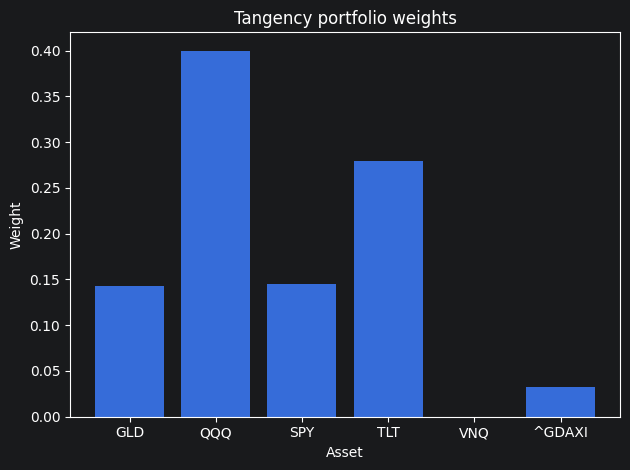

In [ ]:
def plot_tangency_weights(tickers, weights):
    """
    Bar chart of tangency portfolio weights.

    Parameters
    ----------
    tickers : list of str
    weights : array-like of floats (same length as tickers)

    Returns
    -------
    matplotlib.figure.Figure  ← must return the Figure, not None
    """
    
    

    fig, ax = plt.subplots()

    ax.bar(tickers, weights)

    ax.set_title("Tangency portfolio weights")

    ax.set_xlabel("Asset")
    ax.set_ylabel("Weight")

    plt.tight_layout()

    return fig

    raise NotImplementedError("Complete plot_tangency_weights().")


# Store at module level 
portfolio_fig = plot_tangency_weights(tickers, tangency_weights)
plt.show()